# Lab 11-09 · The z-Transform

Companion to [chapter 11-09](../../chapters/11-09-z-transform.md). Four parts: ROCs as convergence, pole–zero filters on a synthetic ECG, stability and word length, and digitizing an analog equalizer. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

## Part 1 — ROCs as convergence of partial sums

Example 11-09.2: $X(z) = 1/[(1 - 0.5z^{-1})(1 - 2z^{-1})]$ belongs to three sequences. Sum $x[n]z^{-n}$ over $\lvert n\rvert \le N$ for growing $N$ at three radii.

In [2]:
seqs = {
    "causal (|z| > 2)":       lambda n: np.where(n >= 0, -(1/3) * 0.5**n + (4/3) * 2.0**n, 0.0),
    "two-sided (0.5<|z|<2)":  lambda n: np.where(n >= 0, -(1/3) * 0.5**n, -(4/3) * 2.0**n),
    "anticausal (|z| < 0.5)": lambda n: np.where(n < 0, (1/3) * 0.5**n - (4/3) * 2.0**n, 0.0),
}
X = lambda z: 1 / ((1 - 0.5 / z) * (1 - 2 / z))
with np.errstate(over="ignore", invalid="ignore"):
    for name, x in seqs.items():
        print(name)
        for rad in (0.3, 1.0, 3.0):
            z = rad * np.exp(0.5j)
            sums = []
            for N in (10, 20, 40):
                n = np.arange(-N, N + 1).astype(float)
                sums.append(np.sum(x(n) * z ** (-n)))
            print(f"   |z| = {rad}: N = 10, 20, 40 ->", np.round(np.abs(sums), 4), "   |X(z)| =", round(abs(X(z)), 4))

causal (|z| > 2)
   |z| = 0.3: N = 10, 20, 40 -> [2.65363193e+08 4.60180529e+16 1.38389474e+33]    |X(z)| = 0.1864
   |z| = 1.0: N = 10, 20, 40 -> [2.23679480e+03 2.29099344e+06 2.40227963e+12]    |X(z)| = 1.3426
   |z| = 3.0: N = 10, 20, 40 -> [2.2079 2.2269 2.2266]    |X(z)| = 2.2266
two-sided (0.5<|z|<2)
   |z| = 0.3: N = 10, 20, 40 -> [9.93274000e+01 1.64571342e+04 4.50121369e+08]    |X(z)| = 0.1864
   |z| = 1.0: N = 10, 20, 40 -> [1.3416 1.3426 1.3426]    |X(z)| = 1.3426
   |z| = 3.0: N = 10, 20, 40 -> [1.45981800e+02 8.46668600e+03 2.81480934e+07]    |X(z)| = 2.2266
anticausal (|z| < 0.5)
   |z| = 0.3: N = 10, 20, 40 -> [0.1871 0.1865 0.1864]    |X(z)| = 0.1864
   |z| = 1.0: N = 10, 20, 40 -> [5.60101400e+02 5.72749367e+05 6.00569908e+11]    |X(z)| = 1.3426
   |z| = 3.0: N = 10, 20, 40 -> [2.35056030e+07 1.42130132e+15 5.19650283e+30]    |X(z)| = 2.2266


Each sequence's sums settle only at the radius inside its own ROC, and there they equal $X(z)$.

## Part 2 — Pole–zero filters

First the resonator of Example 11-09.3: geometric magnitude (inverse product of pole distances) against direct evaluation.

In [3]:
r, th = 0.9, math.pi / 4
poles = np.array([r * np.exp(1j * th), r * np.exp(-1j * th)])
a = np.real(np.poly(poles))
w = np.linspace(0, math.pi, 2001)
e = np.exp(1j * w)
geo = 1 / np.prod(np.abs(e[:, None] - poles[None, :]), axis=1)
direct = np.abs(1 / np.polyval(a[::-1], np.exp(-1j * w)))
print("coefficients a:", np.round(a, 4), "  largest difference:", np.max(np.abs(geo - direct)))
print("peak", round(direct.max(), 3), "at omega/pi =", round(w[np.argmax(direct)] / math.pi, 4))

coefficients a: [ 1.     -1.2728  0.81  ]   largest difference: 1.2434497875801753e-14
peak 7.443 at omega/pi = 0.248


Now a synthetic ECG at 500 SPS (P wave, QRS complex and T wave as Gaussian bumps, 72 beats per minute) with 60 Hz hum, through the three-tap FIR notch of 11-07 and the IIR notch of Example 11-09.4.

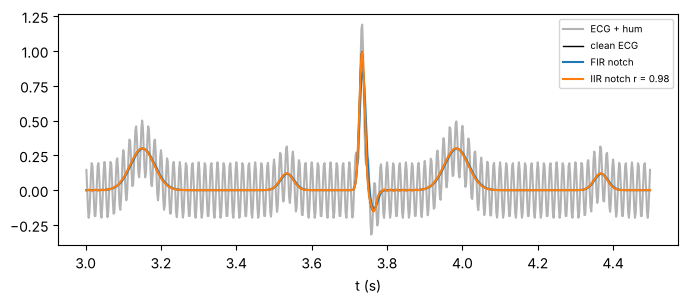

RMS error vs clean ECG after 2 s:  FIR 0.0281   IIR 0.0031


In [4]:
fs = 500.0
t = np.arange(0, 6, 1 / fs)
def beat(tt):
    return (0.12 * np.exp(-((tt - 0.20) / 0.025)**2) + 1.0 * np.exp(-((tt - 0.40) / 0.010)**2)
            - 0.15 * np.exp(-((tt - 0.43) / 0.012)**2) + 0.30 * np.exp(-((tt - 0.65) / 0.045)**2))
ecg = sum(beat(t - k * 60 / 72) for k in range(10))
hum = 0.2 * np.cos(2 * math.pi * 60 * t)
x = ecg + hum

w0 = 2 * math.pi * 60 / fs
bF = np.array([1, -2 * math.cos(w0), 1]); bF = bF / bF.sum()
rr = 0.98
bN = np.array([1, -2 * math.cos(w0), 1]); aN = np.array([1, -2 * rr * math.cos(w0), rr * rr])
bN = bN * aN.sum() / bN.sum()
yF = signal.lfilter(bF, [1.0], x)
yN = signal.lfilter(bN, aN, x)
sl = (t > 3) & (t < 4.5)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t[sl], x[sl], color="0.7", label="ECG + hum")
ax.plot(t[sl], ecg[sl], "k", lw=1, label="clean ECG")
ax.plot(t[sl], yF[sl], label="FIR notch")
ax.plot(t[sl], yN[sl], label="IIR notch r = 0.98")
ax.legend(fontsize=7); ax.set_xlabel("t (s)")
plt.show()
print("RMS error vs clean ECG after 2 s:  FIR", round(np.sqrt(np.mean((yF - ecg)[t > 2]**2)), 4),
      "  IIR", round(np.sqrt(np.mean((yN[t > 2] - ecg[t > 2])**2)), 4))

Measured gain at 50 Hz (least-squares amplitude fit of the steady-state output):

In [5]:
n = np.arange(20000)
y50 = signal.lfilter(bN, aN, np.cos(2 * math.pi * 50 / fs * n))[10000:]
m = n[10000:]
coef = np.linalg.lstsq(np.column_stack([np.cos(2 * math.pi * 50 / fs * m), np.sin(2 * math.pi * 50 / fs * m)]), y50, rcond=None)[0]
print("IIR notch gain at 50 Hz:", round(float(np.hypot(*coef)), 4))

IIR notch gain at 50 Hz: 0.9879


**Guided exercise.** *Predict first:* the hum doubles at $t$ = 2 s. How many samples until the notch's output transient falls to 1% of the jump, for $r$ = 0.98 and $r$ = 0.995? Then run the cell. The envelope of the transient is $r^n$.

In [6]:
for r_ in (0.98, 0.995):
    a_ = np.array([1, -2 * r_ * math.cos(w0), r_ * r_]); b_ = np.array([1, -2 * math.cos(w0), 1]) * a_.sum() / 2 / (1 - math.cos(w0))
    tt = np.arange(0, 8, 1 / fs)
    h = np.where(tt < 2, 0.2, 0.4) * np.cos(2 * math.pi * 60 * tt)
    y = signal.lfilter(b_, a_, h)
    after = np.abs(y[tt >= 2])
    last_big = np.max(np.nonzero(after > 0.01 * 0.2)[0])
    print(f"r = {r_}: envelope r^n reaches 1% after {math.ceil(math.log(0.01) / math.log(r_))} samples;"
          f" measured output last exceeds 1% of the jump at sample {last_big}")

r = 0.98: envelope r^n reaches 1% after 228 samples; measured output last exceeds 1% of the jump at sample 225
r = 0.995: envelope r^n reaches 1% after 919 samples; measured output last exceeds 1% of the jump at sample 908


## Part 3 — Stability and word length

The stability triangle, and every pole a biquad can realize when $a_1$ and $a_2$ are multiples of $2^{-4}$.

complex pole pairs realizable inside the circle with 4 fractional bits: 641


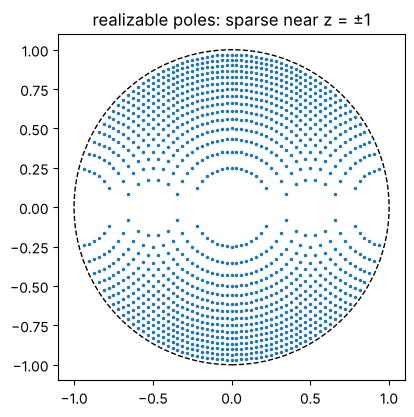

In [7]:
q = 1 / 16
pts = []
for i in range(-64, 64):
    for k in range(-32, 32):
        a1, a2 = i * q, k * q
        if abs(a2) < 1 and abs(a1) < 1 + a2 and a1 * a1 < 4 * a2:
            pts.append(np.roots([1, a1, a2])[0])
pts = np.array(pts)
print("complex pole pairs realizable inside the circle with 4 fractional bits:", len(pts))
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(pts.real, pts.imag, ".", ms=3)
ax.plot(pts.real, -pts.imag, ".", ms=3, color="C0")
ax.add_patch(plt.Circle((0, 0), 1, fill=False, ls="--"))
ax.set_aspect("equal"); ax.set_title("realizable poles: sparse near z = ±1")
plt.show()

## Part 4 — Digitizing the CTLE

11-08's reference CTLE at $g_{DC}$ = −12 dB, converted with the bilinear transform at $M$ samples per UI, and compared with the analog gain at Nyquist. Then prewarp the pole and zero frequencies for $M$ = 2.

In [8]:
fb = 53.125e9; fz = fp1 = 21.25e9; fp2 = 53.125e9; G = 10 ** (-12 / 20)
Ha = lambda f: (G + 1j * f / fz) / ((1 + 1j * f / fp1) * (1 + 1j * f / fp2))
def digital(M, fzz=fz * G, f1=fp1, f2=fp2):
    fs = fb * M
    k = (2 * math.pi * f1) * (2 * math.pi * f2) / (2 * math.pi * fzz) * G
    zd, pd, kd = signal.bilinear_zpk([-2 * math.pi * fzz], [-2 * math.pi * f1, -2 * math.pi * f2], k, fs)
    return fs, zd, pd, kd
ref = 20 * math.log10(abs(Ha(fb / 2)))
for M in (2, 4, 8, 32):
    fs, zd, pd, kd = digital(M)
    _, h = signal.freqz_zpk(zd, pd, kd, worN=[math.pi / M])
    print(f"M = {M:2d}: Nyquist gain {20 * math.log10(abs(h[0])):.3f} dB, error {20 * math.log10(abs(h[0])) - ref:+.3f} dB")
# prewarping: scale the bilinear constant so that Nyquist lands exactly (fs_pw replaces fs in 2*fs)
for M in (2, 4):
    wN = math.pi / M
    fs_pw = (2 * math.pi * fb / 2) / (2 * math.tan(wN / 2))
    k = (2 * math.pi * fp1) * (2 * math.pi * fp2) / (2 * math.pi * fz)
    zd, pd, kd = signal.bilinear_zpk([-2 * math.pi * fz * G], [-2 * math.pi * fp1, -2 * math.pi * fp2], k, fs_pw)
    _, h = signal.freqz_zpk(zd, pd, kd, worN=[wN, wN / 2, 1e-6])
    print(f"M = {M} prewarped at Nyquist: Nyquist error {20 * math.log10(abs(h[0])) - ref:+.4f} dB, "
          f"error at fb/4 {20 * math.log10(abs(h[1])) - 20 * math.log10(abs(Ha(fb / 4))):+.3f} dB, DC {20 * math.log10(abs(h[2])):.3f} dB")

M =  2: Nyquist gain -2.816 dB, error +0.130 dB
M =  4: Nyquist gain -2.884 dB, error +0.061 dB
M =  8: Nyquist gain -2.929 dB, error +0.017 dB
M = 32: Nyquist gain -2.945 dB, error +0.001 dB
M = 2 prewarped at Nyquist: Nyquist error -0.0000 dB, error at fb/4 -0.886 dB, DC -12.000 dB
M = 4 prewarped at Nyquist: Nyquist error -0.0000 dB, error at fb/4 -0.185 dB, DC -12.000 dB


The error falls roughly as $1/M^2$. Prewarping makes the response exact at the chosen frequency (here Nyquist) and leaves DC exact, but other frequencies are still warped: at $M$ = 2 the error simply moves elsewhere in the band. (Prewarping each pole and zero frequency separately does not work here: at $M$ = 2 the second pole sits at $f_s/2$, and the tangent sends it to infinity.)